# Cycle 1 — SDG 7: Exploratory Analysis

**Question:** *Since 2015, electricity access has expanded rapidly across the developing world.
Has clean cooking kept pace — and where is the gap widest and still growing?*

This notebook explores the metrics built by `03_derive_metrics.py` and drafts each chart in
matplotlib before the strongest ones are rebuilt in Tableau. Charts are saved to
`outputs/figures/` for the slide deck.

**Key metric:** `cooking_gap = electricity access % − clean cooking access %`, in percentage
points (pp). A *positive* gap means electricity is ahead. A *negative change* means the gap
narrowed (improving).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

PROC = Path.cwd().parent / "data" / "processed"
FIGS = Path.cwd().parent / "outputs" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

# Palette: validated against the colourblind / contrast checks (see dataviz skill).
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8a85", "#e5e4e0"
GRAY = "#c3c2bd"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.linewidth": 0.8,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.labelsize": 9.5, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.7,
    "legend.frameon": False, "legend.fontsize": 9,
    "font.size": 10,
})

def finish(ax, title, subtitle=None, source="UN SDG API (v5) · 7.1.1 World Bank, 7.1.2 WHO GHO"):
    """Title states the finding; subtitle carries the detail; source always cited."""
    ax.set_title(title, loc="left", pad=18 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9.5, color=INK2, va="bottom")
    ax.figure.text(0.0, -0.04, source, fontsize=7.5, color=MUTED, ha="left")

ELEC, COOK = "EG_ACS_ELEC", "EG_EGY_CLEAN"
metrics = pd.read_csv(PROC / "sdg7_country_metrics.csv")
summary = pd.read_csv(PROC / "sdg7_country_summary.csv")
regions = pd.read_csv(PROC / "sdg7_region_summary.csv")
regions_long = pd.read_csv(PROC / "sdg7_regions.csv")
print(f"{len(metrics)} country-years · {len(summary)} countries · {len(regions)} groupings")

2279 country-years · 228 countries · 11 groupings


## 1. Has clean cooking kept pace globally?

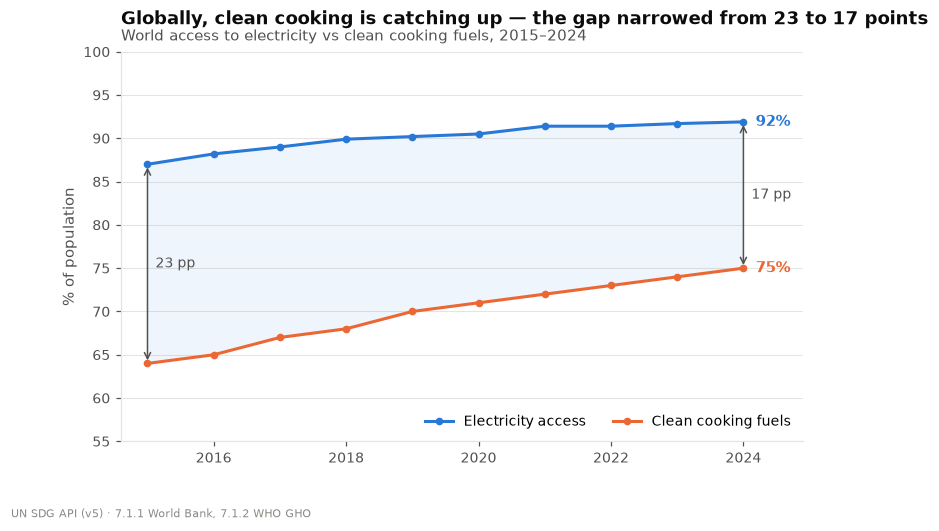

electricity  87.0 -> 91.9  (+4.9 pp)
clean cooking 64.0 -> 75.0  (+11.0 pp)


In [2]:
w = (regions_long[(regions_long.area == "World") & (regions_long.location == "ALLAREA")
                  & regions_long.series.isin([ELEC, COOK])]
     .pivot_table(index="year", columns="series", values="value").sort_index())

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.fill_between(w.index, w[COOK], w[ELEC], color=BLUE, alpha=0.07, lw=0)
ax.plot(w.index, w[ELEC], color=BLUE, lw=2, marker="o", ms=4, label="Electricity access")
ax.plot(w.index, w[COOK], color=ORANGE, lw=2, marker="o", ms=4, label="Clean cooking fuels")

for col, color, name in [(ELEC, BLUE, "Electricity"), (COOK, ORANGE, "Clean cooking")]:
    ax.annotate(f"{w[col].iloc[-1]:.0f}%", (w.index[-1], w[col].iloc[-1]),
                xytext=(8, 0), textcoords="offset points", color=color,
                fontsize=10, fontweight="bold", va="center")

for yr in (2015, 2024):
    gap = w.loc[yr, ELEC] - w.loc[yr, COOK]
    ax.annotate("", xy=(yr, w.loc[yr, ELEC]), xytext=(yr, w.loc[yr, COOK]),
                arrowprops=dict(arrowstyle="<->", color=INK2, lw=1))
    ax.text(yr + 0.12, (w.loc[yr, ELEC] + w.loc[yr, COOK]) / 2, f"{gap:.0f} pp",
            fontsize=9, color=INK2, va="center")

ax.set_ylim(55, 100); ax.set_xlim(2014.6, 2024.9)
ax.set_ylabel("% of population"); ax.grid(axis="y"); ax.set_axisbelow(True)
ax.legend(loc="lower right", ncol=2)
finish(ax, "Globally, clean cooking is catching up — the gap narrowed from 23 to 17 points",
       "World access to electricity vs clean cooking fuels, 2015–2024")
plt.savefig(FIGS / "01_world_trend.png"); plt.show()

print(f"electricity  {w[ELEC].iloc[0]:.1f} -> {w[ELEC].iloc[-1]:.1f}  ({w[ELEC].iloc[-1]-w[ELEC].iloc[0]:+.1f} pp)")
print(f"clean cooking {w[COOK].iloc[0]:.1f} -> {w[COOK].iloc[-1]:.1f}  ({w[COOK].iloc[-1]-w[COOK].iloc[0]:+.1f} pp)")

**Finding.** Yes — globally clean cooking *outpaced* electricity (+11 pp vs +4.9 pp) and the gap
narrowed. Electricity looks slow only because rich regions are already at ~100%.
This is the global average. The next cell breaks it apart.

## 2. Which regions are closing the gap, and which are not?

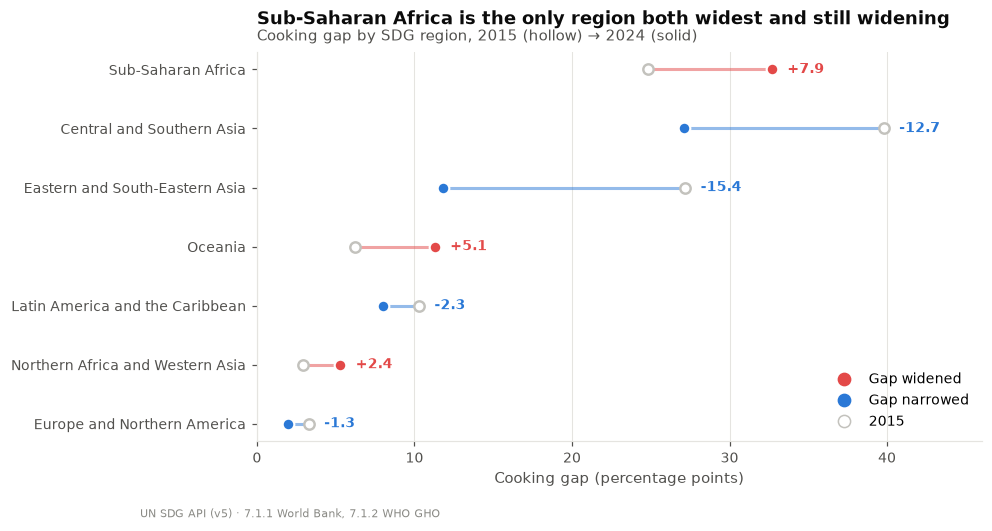

                            area  gap_2015  gap_2024  gap_change
     Europe and Northern America       3.3       2.0        -1.3
Northern Africa and Western Asia       2.9       5.3         2.4
 Latin America and the Caribbean      10.3       8.0        -2.3
                         Oceania       6.2      11.3         5.1
  Eastern and South-Eastern Asia      27.2      11.8       -15.4
       Central and Southern Asia      39.8      27.1       -12.7
              Sub-Saharan Africa      24.8      32.7         7.9


In [3]:
r = (regions[regions.grouping_type == "sdg_region"]
     .sort_values("gap_2024").reset_index(drop=True))
y = np.arange(len(r))

fig, ax = plt.subplots(figsize=(8.5, 4.6))
for i, row in r.iterrows():
    widened = row.gap_change > 0
    color = RED if widened else BLUE
    ax.plot([row.gap_2015, row.gap_2024], [i, i], color=color, lw=2, alpha=0.5,
            solid_capstyle="round", zorder=1)
    ax.scatter(row.gap_2015, i, s=46, color="white", edgecolor=GRAY, lw=1.6, zorder=2)
    ax.scatter(row.gap_2024, i, s=58, color=color, edgecolor="white", lw=1.4, zorder=3)
    ax.annotate(f"{row.gap_change:+.1f}", (max(row.gap_2015, row.gap_2024), i),
                xytext=(10, 0), textcoords="offset points", color=color,
                fontsize=9, fontweight="bold", va="center")

ax.set_yticks(y); ax.set_yticklabels(r.area)
ax.set_xlabel("Cooking gap (percentage points)"); ax.set_xlim(0, 46)
ax.grid(axis="x"); ax.set_axisbelow(True)

from matplotlib.lines import Line2D
ax.legend(handles=[
    Line2D([], [], marker="o", color=RED, lw=0, ms=8, label="Gap widened"),
    Line2D([], [], marker="o", color=BLUE, lw=0, ms=8, label="Gap narrowed"),
    Line2D([], [], marker="o", color="white", markeredgecolor=GRAY, lw=0, ms=8, label="2015"),
], loc="lower right")
finish(ax, "Sub-Saharan Africa is the only region both widest and still widening",
       "Cooking gap by SDG region, 2015 (hollow) → 2024 (solid)")
plt.savefig(FIGS / "02_region_slope.png"); plt.show()
print(r[["area", "gap_2015", "gap_2024", "gap_change"]].round(1).to_string(index=False))

**Finding.** Four regions narrowed, three widened. **Sub-Saharan Africa is the only region that
is simultaneously the widest (32.7 pp) and still widening (+7.9 pp)** — it moved in the opposite
direction to the global trend. This contradiction is the analytical core of the project.

## 3. Where is the gap widest? (a question about *level*)

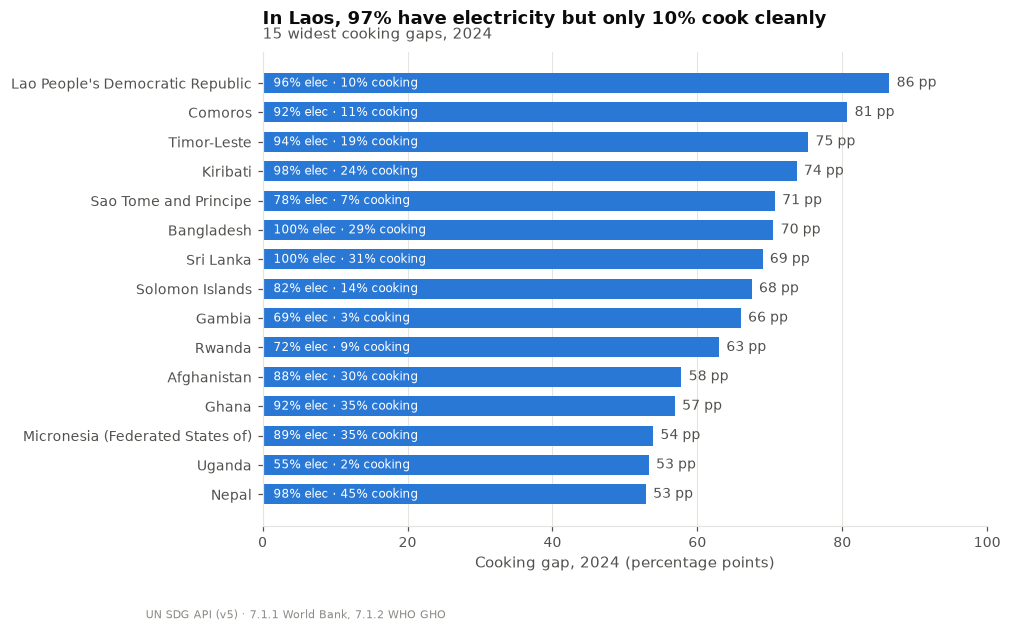

In [4]:
top = summary.dropna(subset=["gap_2024"]).nlargest(15, "gap_2024").iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5.6))
bars = ax.barh(top.country, top.gap_2024, color=BLUE, height=0.68)
for bar, (_, row) in zip(bars, top.iterrows()):
    ax.text(row.gap_2024 + 1, bar.get_y() + bar.get_height()/2,
            f"{row.gap_2024:.0f} pp", va="center", fontsize=9, color=INK2)
    ax.text(1.5, bar.get_y() + bar.get_height()/2,
            f"{row.elec_2024:.0f}% elec · {row.cook_2024:.0f}% cooking",
            va="center", fontsize=8, color="white")
ax.set_xlim(0, 100); ax.set_xlabel("Cooking gap, 2024 (percentage points)")
ax.grid(axis="x"); ax.set_axisbelow(True)
finish(ax, "In Laos, 97% have electricity but only 10% cook cleanly",
       "15 widest cooking gaps, 2024")
plt.savefig(FIGS / "03_widest_gaps.png"); plt.show()

## 4. Where is the gap still growing? (a question about *change*)

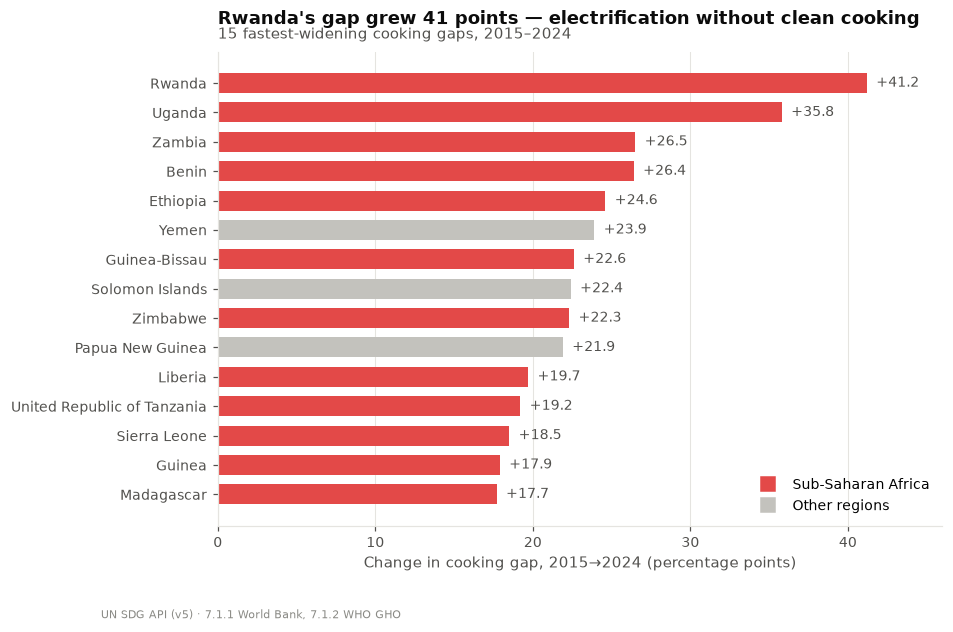

countries in BOTH top-15 lists: ['Rwanda', 'Solomon Islands', 'Uganda']
Sub-Saharan Africa share of fastest-widening 15: 12 of 15


In [5]:
wid = summary.dropna(subset=["gap_change"]).nlargest(15, "gap_change").iloc[::-1]
is_ssa = wid.region == "Sub-Saharan Africa"
fig, ax = plt.subplots(figsize=(8.5, 5.6))
bars = ax.barh(wid.country, wid.gap_change,
               color=[RED if s else GRAY for s in is_ssa], height=0.68)
for bar, v in zip(bars, wid.gap_change):
    ax.text(v + 0.6, bar.get_y() + bar.get_height()/2, f"+{v:.1f}",
            va="center", fontsize=9, color=INK2)
ax.set_xlabel("Change in cooking gap, 2015→2024 (percentage points)")
ax.set_xlim(0, 46); ax.grid(axis="x"); ax.set_axisbelow(True)
ax.legend(handles=[
    Line2D([], [], marker="s", color=RED, lw=0, ms=9, label="Sub-Saharan Africa"),
    Line2D([], [], marker="s", color=GRAY, lw=0, ms=9, label="Other regions"),
], loc="lower right")
finish(ax, "Rwanda's gap grew 41 points — electrification without clean cooking",
       "15 fastest-widening cooking gaps, 2015–2024")
plt.savefig(FIGS / "04_fastest_widening.png"); plt.show()

overlap = set(summary.nlargest(15, "gap_2024").country) & set(summary.nlargest(15, "gap_change").country)
print("countries in BOTH top-15 lists:", sorted(overlap))
print("Sub-Saharan Africa share of fastest-widening 15:", int(is_ssa.sum()), "of 15")

**Finding.** The two lists barely overlap — "widest" and "widening" are genuinely different
questions. The widening list is dominated by Sub-Saharan Africa.

## 5. Did electrification come with clean cooking?

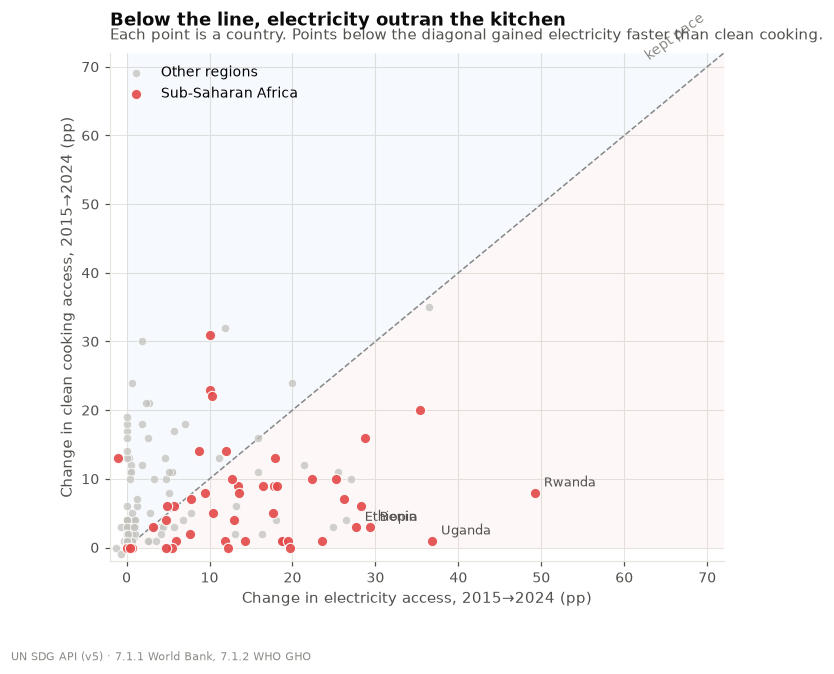

69 of 194 countries gained electricity faster than clean cooking


In [6]:
s = summary.dropna(subset=["elec_change", "cook_change"])
ssa = s[s.region == "Sub-Saharan Africa"]
oth = s[s.region != "Sub-Saharan Africa"]

fig, ax = plt.subplots(figsize=(7.2, 6))
lim = 72
ax.plot([0, lim], [0, lim], color=MUTED, lw=1, ls="--", zorder=1)
ax.text(lim-2, lim-1, "kept pace", color=MUTED, fontsize=9, ha="right", rotation=36)
ax.fill_between([0, lim], [0, lim], [lim, lim], color=BLUE, alpha=0.04, lw=0)
ax.fill_between([0, lim], [0, 0], [0, lim], color=RED, alpha=0.04, lw=0)

ax.scatter(oth.elec_change, oth.cook_change, s=30, color=GRAY, alpha=0.75,
           edgecolor="white", lw=0.6, label="Other regions", zorder=2)
ax.scatter(ssa.elec_change, ssa.cook_change, s=46, color=RED, alpha=0.9,
           edgecolor="white", lw=0.8, label="Sub-Saharan Africa", zorder=3)
for name in ["Rwanda", "Uganda", "Zambia", "Ethiopia", "Benin"]:
    row = s[s.country == name]
    if len(row):
        ax.annotate(name, (row.elec_change.iloc[0], row.cook_change.iloc[0]),
                    xytext=(6, 4), textcoords="offset points", fontsize=8.5, color=INK2)

ax.set_xlabel("Change in electricity access, 2015→2024 (pp)")
ax.set_ylabel("Change in clean cooking access, 2015→2024 (pp)")
ax.set_xlim(-2, lim); ax.set_ylim(-2, lim)
ax.grid(True); ax.set_axisbelow(True); ax.legend(loc="upper left")
finish(ax, "Below the line, electricity outran the kitchen",
       "Each point is a country. Points below the diagonal gained electricity faster than clean cooking.")
plt.savefig(FIGS / "05_scatter_change.png"); plt.show()

below = (s.cook_change < s.elec_change).sum()
print(f"{below} of {len(s)} countries gained electricity faster than clean cooking")

## 6. Inside a country: rural vs urban

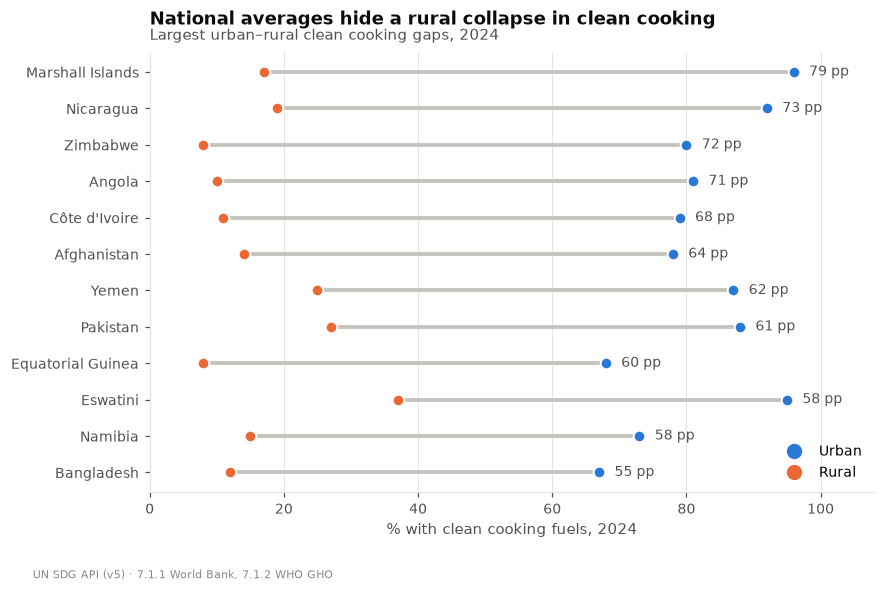

In [7]:
latest = metrics[metrics.year == 2024].dropna(subset=["cook_urban_rural_gap"])
top10 = latest.nlargest(12, "cook_urban_rural_gap").iloc[::-1]
cook = pd.read_csv(PROC / "sdg7_tidy.csv")
cook = cook[(cook.series == COOK) & (cook.year == 2024)
            & cook.location.isin(["URBAN", "RURAL"])]
piv = cook.pivot_table(index="country", columns="location", values="value").loc[top10.country]

fig, ax = plt.subplots(figsize=(8.5, 5.2))
yy = np.arange(len(piv))
for i, (name, row) in enumerate(piv.iterrows()):
    ax.plot([row.RURAL, row.URBAN], [i, i], color=GRAY, lw=2.5, solid_capstyle="round", zorder=1)
    ax.scatter(row.RURAL, i, s=58, color=ORANGE, edgecolor="white", lw=1.3, zorder=3)
    ax.scatter(row.URBAN, i, s=58, color=BLUE, edgecolor="white", lw=1.3, zorder=3)
    ax.annotate(f"{row.URBAN - row.RURAL:.0f} pp", (row.URBAN, i), xytext=(10, 0),
                textcoords="offset points", fontsize=9, color=INK2, va="center")
ax.set_yticks(yy); ax.set_yticklabels(piv.index)
ax.set_xlabel("% with clean cooking fuels, 2024"); ax.set_xlim(0, 108)
ax.grid(axis="x"); ax.set_axisbelow(True)
ax.legend(handles=[
    Line2D([], [], marker="o", color=BLUE, lw=0, ms=9, label="Urban"),
    Line2D([], [], marker="o", color=ORANGE, lw=0, ms=9, label="Rural"),
], loc="lower right")
finish(ax, "National averages hide a rural collapse in clean cooking",
       "Largest urban–rural clean cooking gaps, 2024")
plt.savefig(FIGS / "06_rural_urban.png"); plt.show()

## 7. Pace check: when does universal clean cooking arrive?

In [8]:
# A linear projection only means something where a trend exists. Countries whose fitted
# slope is effectively zero cannot be extrapolated -- dividing by ~0 produces absurd dates
# (Liberia came out at year 2.8e19 before this guard). Report them as "no measurable
# progress" rather than inventing an arrival year.
MIN_SLOPE = 0.1  # pp per year

base = summary.dropna(subset=["gap_change"])   # the 194 countries with both endpoints
print(f"Of the {len(base)} countries with both a 2015 and a 2024 value:")
print(f"  on pace for universal ELECTRICITY by 2030   : {int(base.elec_on_track_2030.sum())}")
print(f"  on pace for universal CLEAN COOKING by 2030 : {int(base.cook_on_track_2030.sum())}")

short = base[base.cook_2024 < 95].copy()
stalled = short[short.cook_slope_per_year < MIN_SLOPE]
moving = short[short.cook_slope_per_year >= MIN_SLOPE].copy()
moving["eta"] = 2024 + (100 - moving.cook_2024) / moving.cook_slope_per_year

print()
print(f"{len(stalled)} countries show no measurable progress (< {MIN_SLOPE} pp/yr) and cannot")
print("be projected at all. Lowest current access among them:")
for _, r in stalled.nsmallest(8, "cook_2024").iterrows():
    print(f"    {r.country:<34} {r.cook_2024:4.0f}%   ({r.region})")

print()
print(f"Slowest projected arrival among the {len(moving)} countries that are moving:")
print(moving.nlargest(8, "eta")[["country", "region", "cook_2024",
                                 "cook_slope_per_year", "eta"]].round(1).to_string(index=False))

Of the 194 countries with both a 2015 and a 2024 value:
  on pace for universal ELECTRICITY by 2030   : 125
  on pace for universal CLEAN COOKING by 2030 : 65

13 countries show no measurable progress (< 0.1 pp/yr) and cannot
be projected at all. Lowest current access among them:
    Burundi                               0%   (Sub-Saharan Africa)
    South Sudan                           0%   (Sub-Saharan Africa)
    Liberia                               1%   (Sub-Saharan Africa)
    Central African Republic              1%   (Sub-Saharan Africa)
    Mali                                  2%   (Sub-Saharan Africa)
    Sierra Leone                          2%   (Sub-Saharan Africa)
    Malawi                                2%   (Sub-Saharan Africa)
    Democratic Republic of the Congo      5%   (Sub-Saharan Africa)

Slowest projected arrival among the 90 countries that are moving:
         country                          region  cook_2024  cook_slope_per_year    eta
           Haiti Lat

> **Caveat for the slide:** this is a straight-line extrapolation of the 2015–2024 trend, so it
> answers *"where does the current pace lead?"* — not *"what will happen."* Access curves flatten
> near 100%, so the projection flatters slow movers.
>
> A group of countries has **no measurable trend at all** — their clean cooking access has not
> moved in ten years. They are excluded from the projection rather than assigned an arrival date,
> because dividing by a near-zero slope yields meaningless numbers. Being unprojectable is itself
> the finding: these are the places where nothing is happening.

---

## Findings to carry into the deck

1. **Globally, clean cooking is catching up.** +11 pp vs +4.9 pp for electricity; the gap narrowed
   23 → 17 pp. The answer to "has it kept pace?" is *yes, on average*.
2. **The average hides a reversal.** Sub-Saharan Africa's gap *widened* 24.8 → 32.7 pp — the only
   region that is both widest and still widening.
3. **"Widest" and "widening" name different countries.** Laos has the widest gap (86.5 pp);
   Rwanda's grew fastest (+41.2 pp). Barely any overlap between the two top-15 lists.
4. **Electrification is outrunning the kitchen in Sub-Saharan Africa specifically**, not worldwide.
5. **Clean cooking is roughly half as likely to be solved**: 125 countries on pace for universal
   electricity by 2030, only 65 for clean cooking.
6. **Rural households are where the deficit lives** — national averages conceal it.

### Charts to rebuild in Tableau
`01_world_trend` (the required change-over-time chart) · `02_region_slope` ·
`03_widest_gaps` or a choropleth of 2024 gap · `06_rural_urban`.